In [1]:
## import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import time
from scipy.integrate import solve_ivp  # type: ignore[import]

# --------------------------------- Internal imports --------------------------------- #
from radiopyo_vec.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo_vec.sim_env import SimEnv
from radiopyo_vec.ode_solver import derive, jacobian
from radiopyo_vec.sim_hand import UnitCell
from radiopyo_vec.sim_utils import SimUtils
import radiopyo_vec as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

In [3]:
def matprint(mat, fmt="g"):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
        print("")

### Prepare Sim Env

In [4]:
file = Path(rf"{rp.__path__[0]}\data\reactions_rudi.ron")
beam = ConstantBeam(1e3, max_dose=10)
#beam = PulsedBeam(1000, max_dose=13, period=0.5, on_time=500e-6)
#beam = PulsedBeam.from_peak_dose_rate(1000, period=10, on_time=1e-3, max_dose=13)
sim = UnitCell(file, beam=beam)

In [5]:
for reaction in sim.env.reactions.radiolytic:
    print(reaction)

Radiolytic<e_aq, Ge:2.80, index:0>
Radiolytic<OH_r, Ge:2.80, index:1>
Radiolytic<H_r, Ge:0.62, index:2>
Radiolytic<H2, Ge:0.47, index:3>
Radiolytic<H2O2, Ge:0.73, index:4>
Radiolytic<R_r, Ge:0.59, index:5>


## Run Sim

In [8]:
sim.set_beam(PulsedBeam.from_peak_dose_rate(1e3, period=25e-3, on_time=1e-3, max_dose=5))


In [9]:
sim.beam.make_matrix(0, 1)

array([[1.026e+00, 0.000e+00],
       [1.025e+00, 0.000e+00],
       [1.001e+00, 0.000e+00],
       [1.000e+00, 0.000e+00],
       [9.760e-01, 0.000e+00],
       [9.750e-01, 0.000e+00],
       [9.510e-01, 0.000e+00],
       [9.500e-01, 0.000e+00],
       [9.260e-01, 0.000e+00],
       [9.250e-01, 0.000e+00],
       [9.010e-01, 0.000e+00],
       [9.000e-01, 0.000e+00],
       [8.760e-01, 0.000e+00],
       [8.750e-01, 0.000e+00],
       [8.510e-01, 0.000e+00],
       [8.500e-01, 0.000e+00],
       [8.260e-01, 0.000e+00],
       [8.250e-01, 0.000e+00],
       [8.010e-01, 0.000e+00],
       [8.000e-01, 0.000e+00],
       [7.760e-01, 0.000e+00],
       [7.750e-01, 0.000e+00],
       [7.510e-01, 0.000e+00],
       [7.500e-01, 0.000e+00],
       [7.260e-01, 0.000e+00],
       [7.250e-01, 0.000e+00],
       [7.010e-01, 0.000e+00],
       [7.000e-01, 0.000e+00],
       [6.760e-01, 0.000e+00],
       [6.750e-01, 0.000e+00],
       [6.510e-01, 0.000e+00],
       [6.500e-01, 0.000e+00],
       [

In [8]:
sim.beam.make_time_intervals(0, 1)

array([1.026  , 1.02495, 1.00105, 0.99995, 0.97605, 0.97495, 0.95105,
       0.94995, 0.92605, 0.92495, 0.90105, 0.89995, 0.87605, 0.87495,
       0.85105, 0.84995, 0.82605, 0.82495, 0.80105, 0.79995, 0.77605,
       0.77495, 0.75105, 0.74995, 0.72605, 0.72495, 0.70105, 0.69995,
       0.67605, 0.67495, 0.65105, 0.64995, 0.62605, 0.62495, 0.60105,
       0.59995, 0.57605, 0.57495, 0.55105, 0.54995, 0.52605, 0.52495,
       0.50105, 0.49995, 0.47605, 0.47495, 0.45105, 0.44995, 0.42605,
       0.42495, 0.40105, 0.39995, 0.37605, 0.37495, 0.35105, 0.34995,
       0.32605, 0.32495, 0.30105, 0.29995, 0.27605, 0.27495, 0.25105,
       0.24995, 0.22605, 0.22495, 0.20105, 0.19995, 0.17605, 0.17495,
       0.15105, 0.14995, 0.12605, 0.12495, 0.10105, 0.09995, 0.07605,
       0.07495, 0.05105, 0.04995, 0.02605, 0.02495, 0.00105, 0.     ])

In [9]:
sim.set_beam(ConstantBeam(1e7, max_dose=10))

print(f"Running simulation at {sim.beam.dose_rate} Gy/s", end="")
sol = sim.run_chunked([1e-9, 0.25, 0.35, 0.5, 1.0, 10], use_jac=True, method="LSODA")

sim_t, res = sol.t, sol.y
print(f"\t==> Execution time was {sim.last_exec_time:.3f} s")
print(f"\t Number of function evaluation is: {sol.nfev}")

Running simulation at 10000000.0 Gy/s	==> Execution time was 0.020 s
	 Number of function evaluation is: [631, 48, 46, 61, 92]


In [15]:
len(sim_t)

533

In [6]:
sim.set_beam(PulsedBeam.from_peak_dose_rate(1e3, period=25e-3, on_time=1e-3, max_dose=50))

print(f"Running simulation at {sim.beam.dose_rate} Gy/s", end="")
t_span = [1e-9, 10]
tlog = np.arange(-9, -2.9, step=0.1)
t_loc = np.power(10, tlog)
t_loc = np.append(t_loc, np.arange(2e-3, t_span[1], step=1e-3))
sol = sim.run([1e-9, 10], use_jac=True, method="Radau", t_eval=t_loc)

sim_t, res = sol.t, sol.y
print(f"\t==> Execution time was {sim.exec_time:.3f} s")
print(f"\t Number of function evaluation is: {sol.nfev}")

Running simulation at 40.0 Gy/s

KeyboardInterrupt: 

## Old way of running sim

In [26]:
beam = ConstantBeam(1, max_dose=10)
kwargs = {}
if isinstance(beam, ConstantBeam):
    kwargs["max_step"] = np.inf
else:
    kwargs["max_step"] = beam.timer.on_time/10
    
kwargs["first_step"] = 1e-15
kwargs["atol"] = 1e-15
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 500]
tlog = np.arange(-9, -2.9, step=0.1)
tspan = np.power(10, tlog)
tspan = np.append(tspan, np.arange(2e-3, t_span[1], step=1e-3))
y0 = sim.env.initial_values()
ab_mat = sim.env.make_acidBase_matrix()
ki_mat = sim.env.make_kreaction_matrix()
Gi_mat = sim.env.make_radiolytic_vector()
Enzi   = sim.env.make_enzymatic_matrix()

In [27]:
print(f"Running simulation at {beam.dose_rate} Gy/s", end="")
t0 = time.time()
sol = solve_ivp(derive,
                t_span,
                y0,
                args=(beam, ab_mat, ki_mat, Gi_mat, Enzi),
                t_eval=tspan,
                #jac=jac,
                **kwargs)
t1 = time.time()

sim_t, res = sol.t, sol.y
print(f"\t==> Execution time was {t1-t0:.3f} s")


Running simulation at 1 Gy/s	==> Execution time was 0.698 s


## Plot

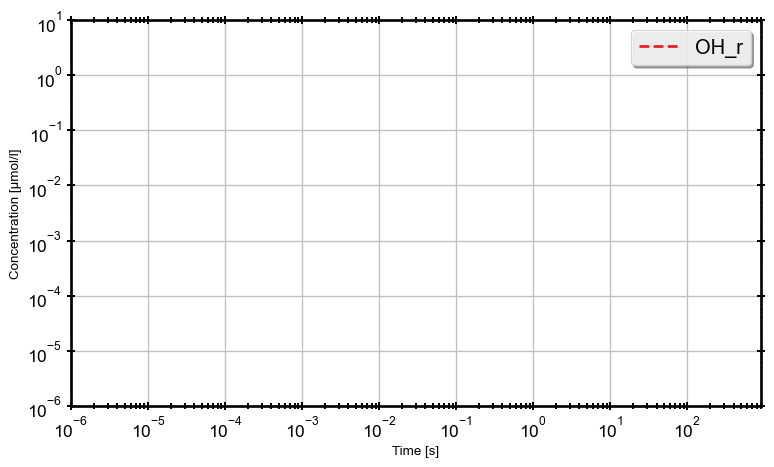

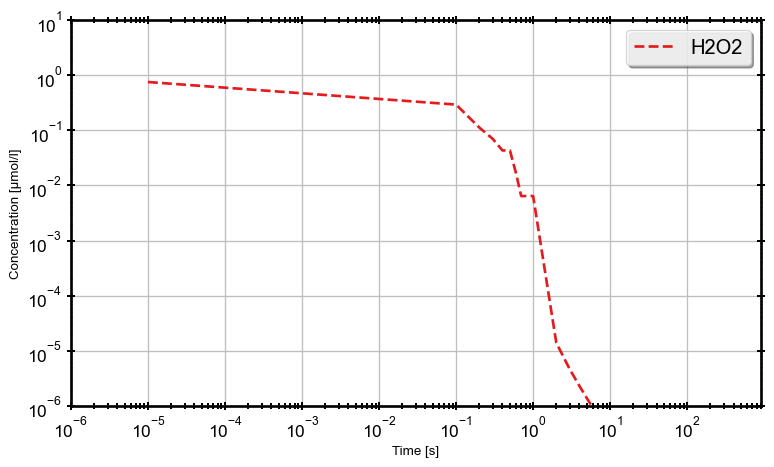

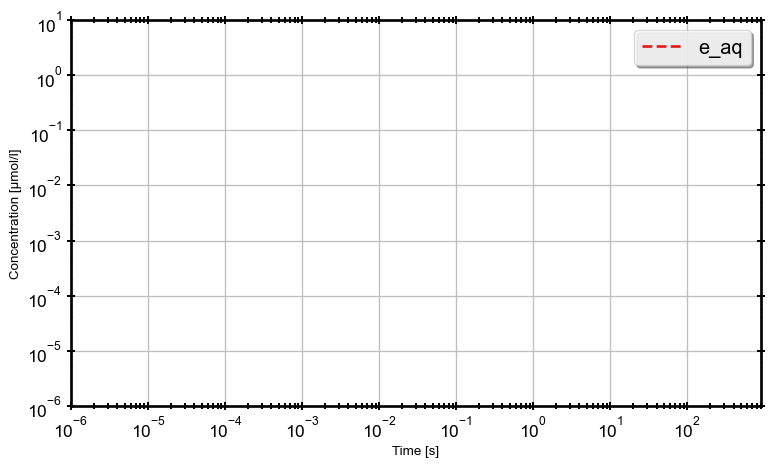

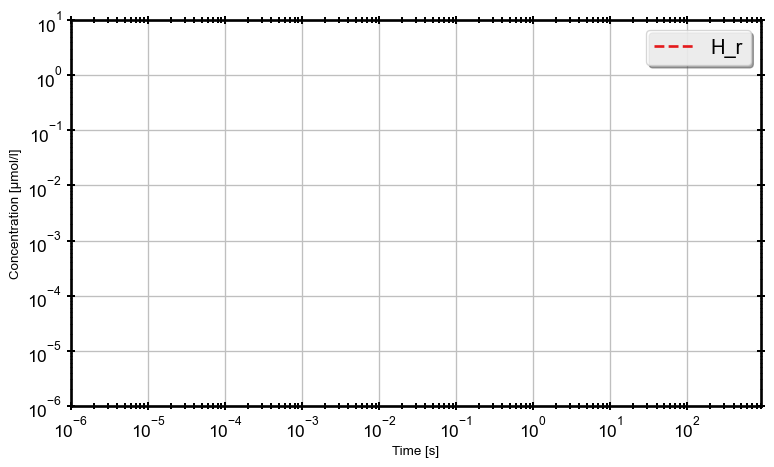

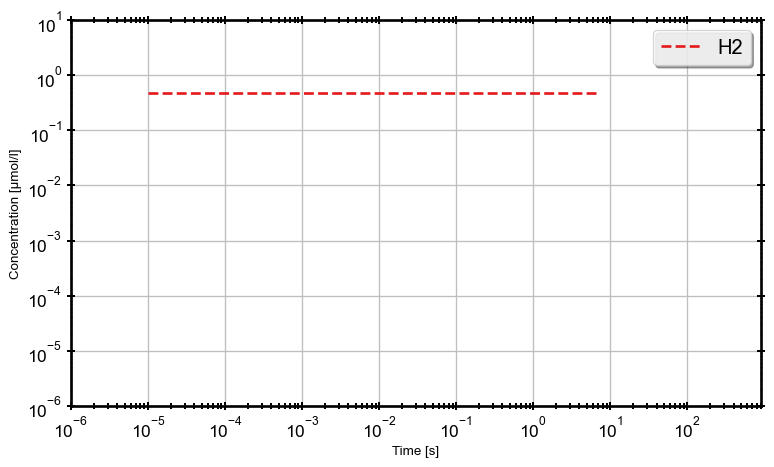

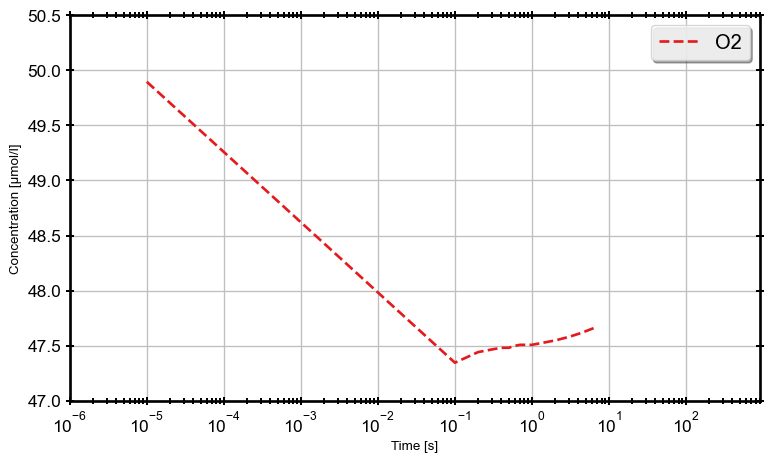

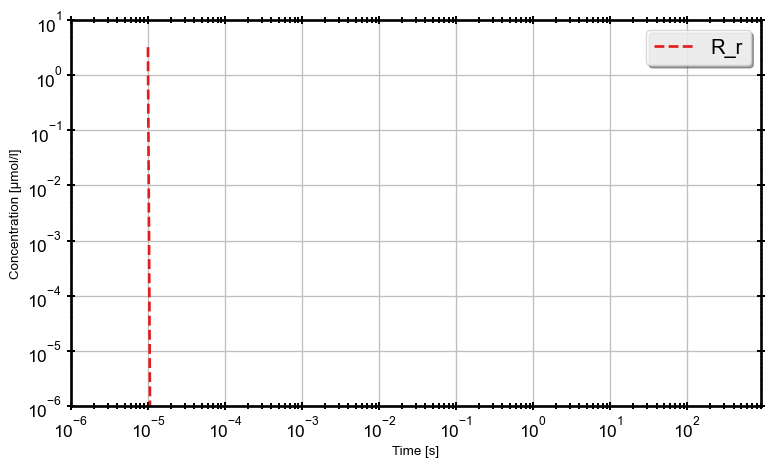

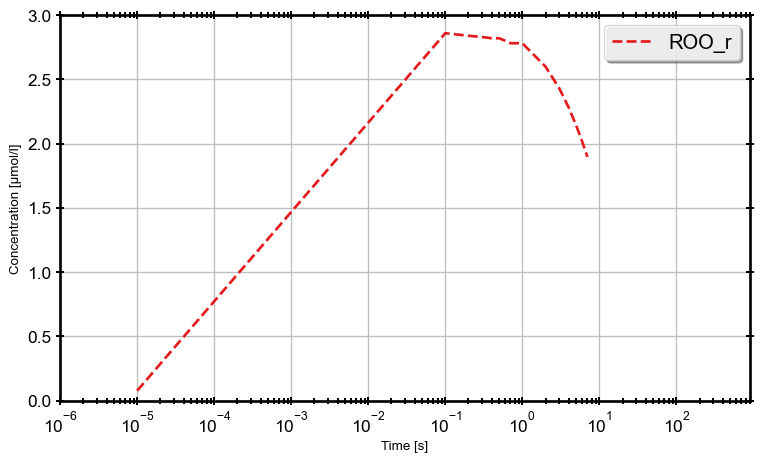

In [12]:
for (label, sp) in zip(sim.env.species_labels(), res):
    if label not in ["OH_r", "H2O2", "e_aq", "H_r", "O2", "H2", "R_r", "ROO_r"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        #sp = sp * 1e6
        if label=="O2":
            ax.plot(sim_t , sp , label=label, marker="")
            ax.set_xlim(left=1e-6, right=900)
            ax.set_xscale("log")
            #ax.set_ylim([49.9, 50.01])
        elif label=="ROO_r":
            ax.plot(sim_t, sp, label=label, marker="")
            ax.set_ylim([0, 3])
            ax.set_xlim(left=1e-6, right=900)
            ax.set_xscale("log")
        else:
            ax.plot(sim_t , sp , label=label, marker="")
            ax.set_ylim(bottom=1e-6, top=10)
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlim(left=1e-6, right=900)
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Explore reaction Rates:

In [13]:
sol.y.shape

(20, 736)

In [117]:
df_r = SimUtils.reconstruct_reactions(sim, sol)
df_b = SimUtils.species_balance_evolution(sim, sol)
df_j = SimUtils.reconstruct_jacobian(sim, sol)

In [118]:
df_r["EZ_0"].sum()

0.0

In [109]:
df_b

,e_aq,H_r,H2,H2O2,O2
1.000000e-09,2.901996e-07,6.425847e-08,4.871207e-08,7.565917e-08,0.0
1.001000e-09,2.901996e-07,6.425847e-08,4.871207e-08,7.565917e-08,0.0
1.002000e-09,2.901996e-07,6.425847e-08,4.871207e-08,7.565917e-08,0.0
1.100200e-08,2.901980e-07,6.426007e-08,4.871207e-08,7.565917e-08,0.0
2.100200e-08,2.901964e-07,6.426166e-08,4.871207e-08,7.565917e-08,0.0
...,...,...,...,...,...
1.677977e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
2.227815e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
7.726204e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
1.322459e+02,-1.161353e-45,1.161353e-45,3.160808e-100,0.000000e+00,0.0


In [119]:
df_j

sp             e_aq                       H_r                      \
dsp           de_aq          dH_r  dH2  de_aq           dH_r  dH2   
1.000000e-09 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
1.001000e-09 -550.0 -3.368631e-36  0.0  550.0  -1.684316e-36  0.0   
1.002000e-09 -550.0 -1.347452e-35  0.0  550.0  -6.737262e-36  0.0   
1.100200e-08 -550.0 -3.369960e-28  0.0  550.0  -1.684980e-28  0.0   
2.100200e-08 -550.0 -1.347707e-27  0.0  550.0  -6.738536e-28  0.0   
...             ...           ...  ...    ...            ...  ...   
1.677977e+01 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
2.227815e+01 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
7.726204e+01 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
1.322459e+02 -550.0  0.000000e+00  0.0  550.0   0.000000e+00  0.0   
5.000000e+02 -550.0 -1.377396e-99  0.0  550.0 -6.886980e-100  0.0   

sp                      H2                      
dsp                  de_aq           dH_r  dH2  
1.000000e-09  0.000000e+00   0.000000e+00  0.0  
1.001000e-09  7.459112e-37   1.684316e-36  0.0  
1.002000e-09  2.983645e-36   6.737262e-36  0.0  
1.100200e-08  7.462168e-29   1.684980e-28  0.0  
2.100200e-08  2.984299e-28   6.738536e-28  0.0  
...                    ...            ...  ...  
1.677977e+01  0.000000e+00   0.000000e+00  0.0  
2.227815e+01  0.000000e+00   0.000000e+00  0.0  
7.726204e+01  0.000000e+00   0.000000e+00  0.0  
1.322459e+02  0.000000e+00   0.000000e+00  0.0  
5.000000e+02  8.320016e-55  6.886980e-100  0.0  

[209 rows x 9 columns]

In [26]:
idx_t = 201
print(f"Time is {sol.t[idx_t]}")
for sp in sim.env.iter_DynSpecies():
    _ = f"[{sp.label}]"
    print(f"{_}{' '*(20-len(_))} = {sol.y[sp.index,idx_t]}")

Time is 9.999984001125554
[OH_r]               = 2.7248833159430834e-10
[O_r_minus]          = 3.4304248682405275e-15
[H2O2]               = 0.007987005640842119
[HO2_minus]          = 1.593617136484079e-07
[HO2_r]              = 8.873250809833197e-06
[O2_r_minus]         = 0.0011170760929715099
[e_aq]               = 2.059527627345758e-09
[H_r]                = 6.363034965318453e-10
[H2]                 = 0.48712336535539164
[O2]                 = 47.49642967269943
[O2_minus_minus]     = 2.934764399780768e-07
[O3_minus]           = 6.016909077060928e-09
[Fe_plus_plus_plus]  = 489499.2168061457
[HO_r]               = 489499.2168061457
[RH_r]               = 3.6961152605890013
[R_r]                = 0.00012474902863534044
[ROO_r]              = 2.2591559318963217
[ROH]                = 0.09995960923762189
[RO]                 = 0.09995960923762189
[ROOH]               = 0.0002506213356744712


In [15]:
sol.y[:,
      100]

array([2.72488172e-10, 3.43042285e-15, 1.41072153e-04, 2.81475950e-09,
       3.89029379e-08, 4.89758971e-06, 2.05883419e-09, 6.35972426e-10,
       9.16550118e-05, 4.99995410e+01, 1.23320105e-13, 1.16180910e-12,
       9.21020366e+01, 9.21020366e+01, 6.95317351e-04, 1.18526462e-04,
       4.54653475e-04, 5.39777495e-13, 5.39777495e-13, 7.29821455e-12])

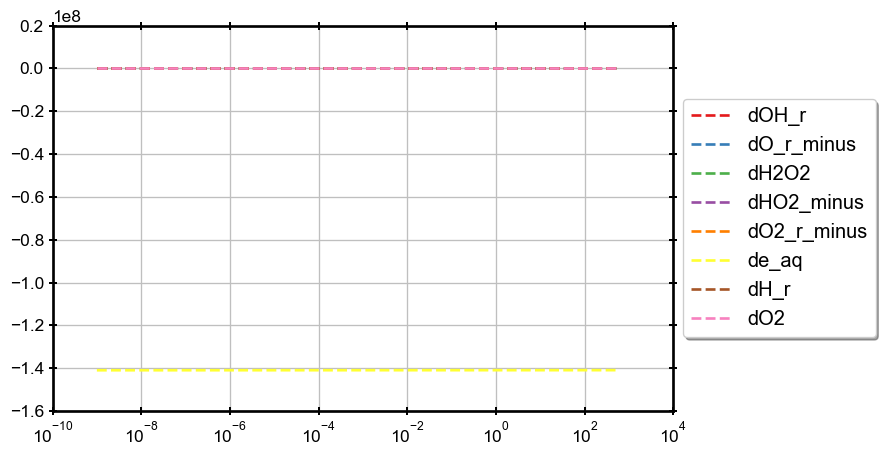

In [13]:
species = "e_aq"
with fig_man.open(f"jacobian evolution for {species}") as (fig, ax):
    for col, s in df_j.xs(species, level="sp", axis=1).items():
        if s.sum() == 0.0:
            continue
        ax.semilogx(s.index, s, label=col, marker="")
    RPlot.set_legend_right(ax)
        

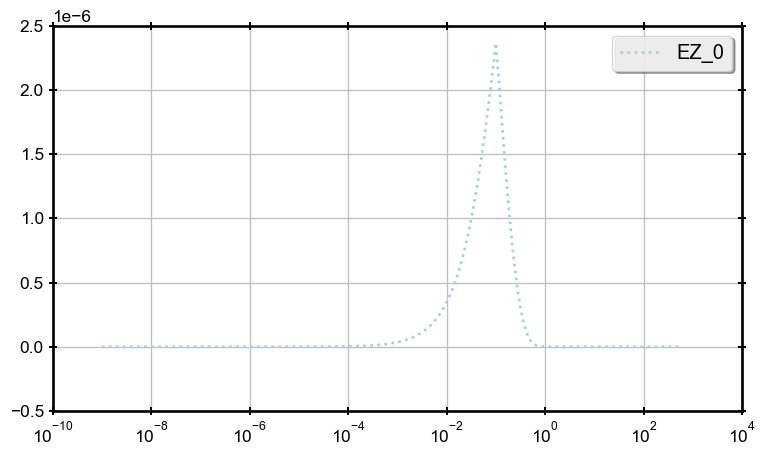

In [12]:
species = "EZ_0"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rate EZ0") as (fig, ax):
    ax.semilogx(df.index, df[species], label=f"EZ_0", marker="", linestyle=":")
    ax.legend()

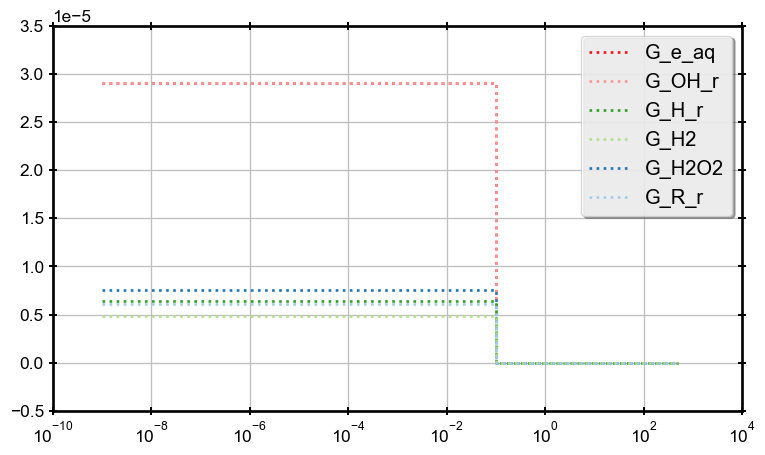

In [13]:
reac = ["G_e_aq", "G_OH_r", "G_H_r", "G_H2", "G_H2O2", "G_R_r"]
fig_man.set_brewer_map("Paired", "qualitative", len(reac), reverse=True)
with fig_man.open(f"Radiolytic reactions") as (fig, ax):
    for label in reac:
        ax.semilogx(df.index, df[label], label=label, marker="", linestyle=":")
    ax.legend()

### Plot reaction rates by species

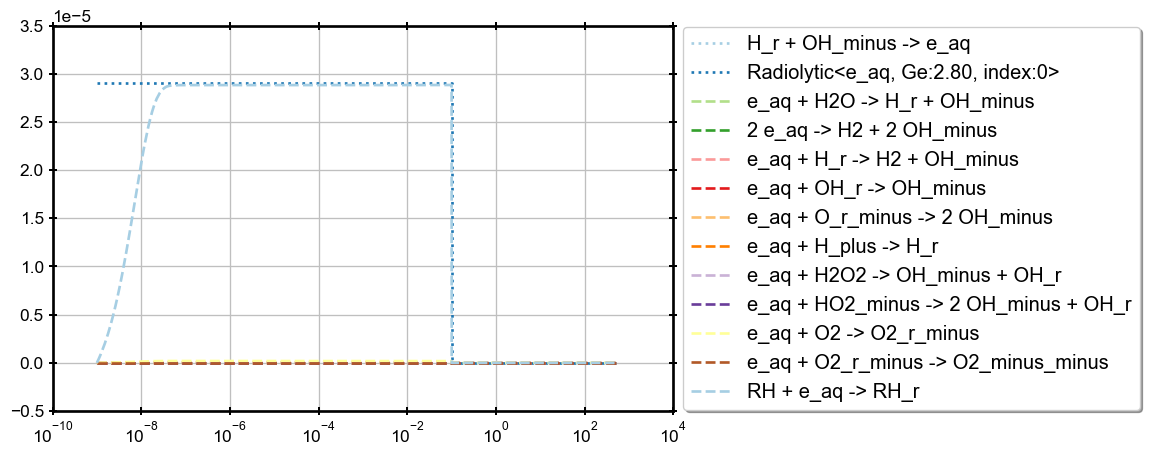

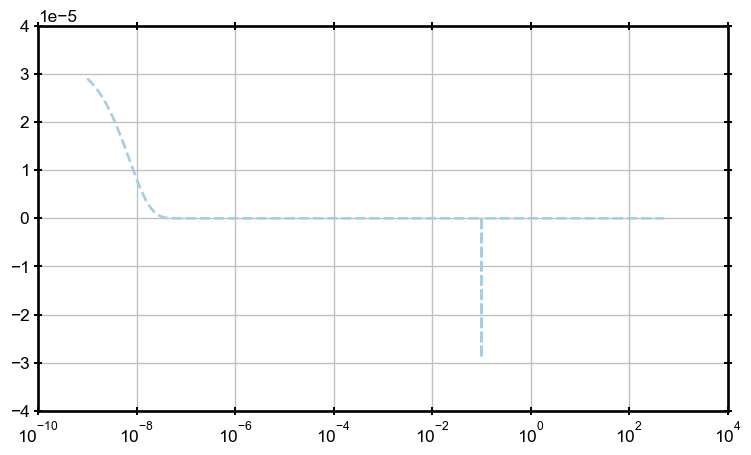

In [12]:
species = "e_aq"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"{reaction}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

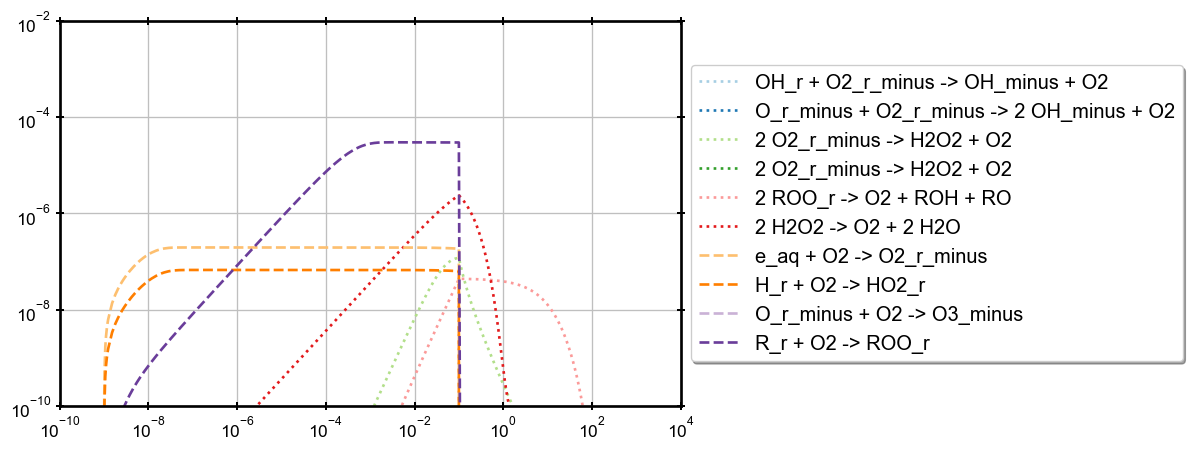

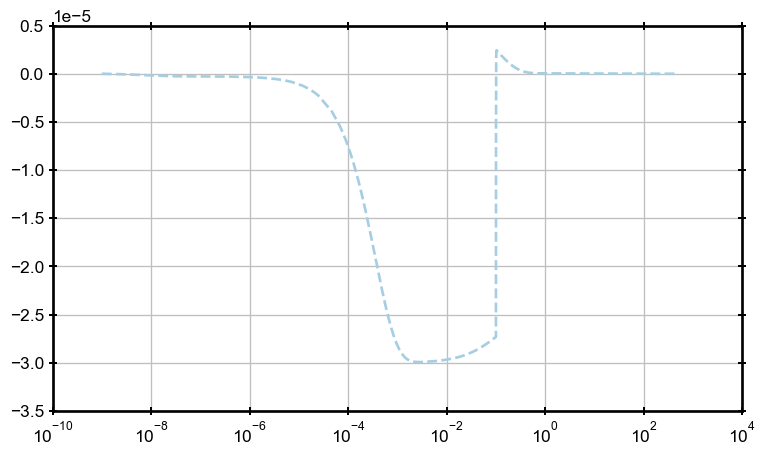

In [11]:
species = "O2"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"{reaction}", marker="", linestyle="--")
    ax.set_ylim(bottom=1e-10)
    RPlot.set_legend_right(ax)
    
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

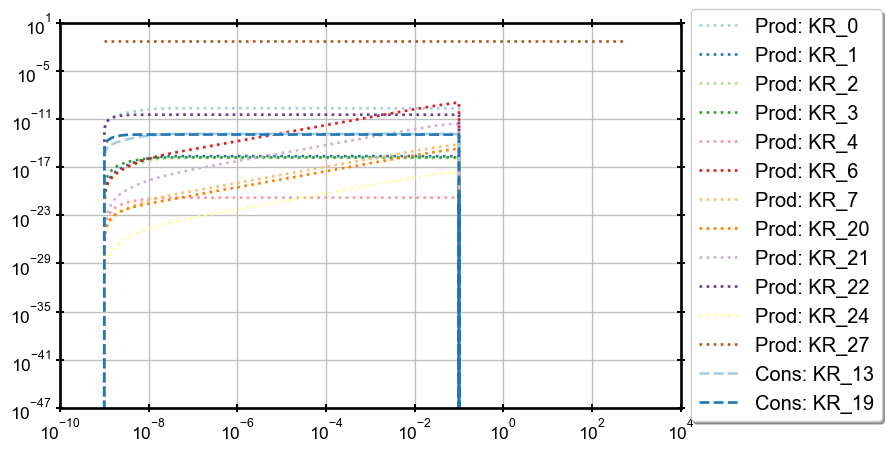

In [14]:
species = "OH_minus"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)

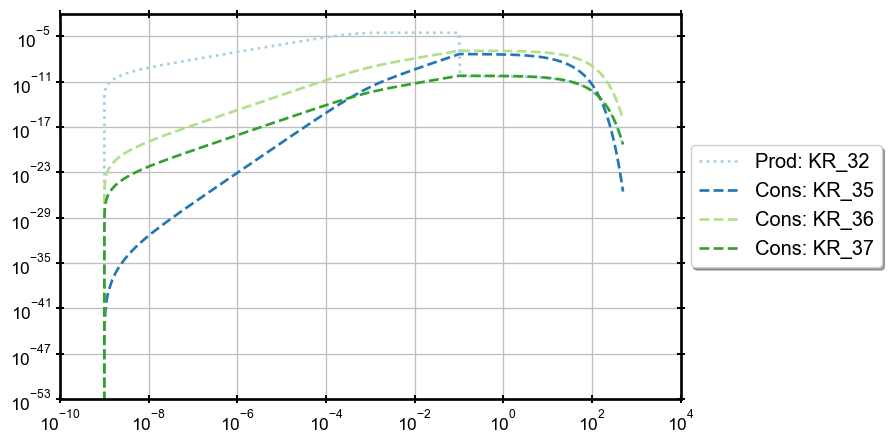

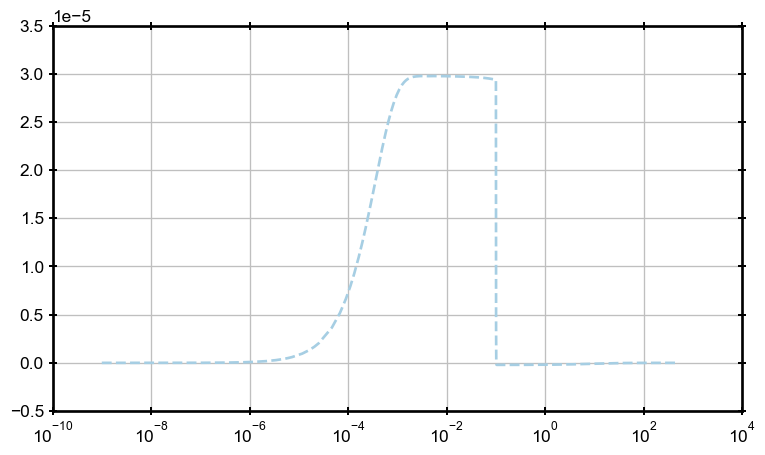

In [15]:
species = "ROO_r"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

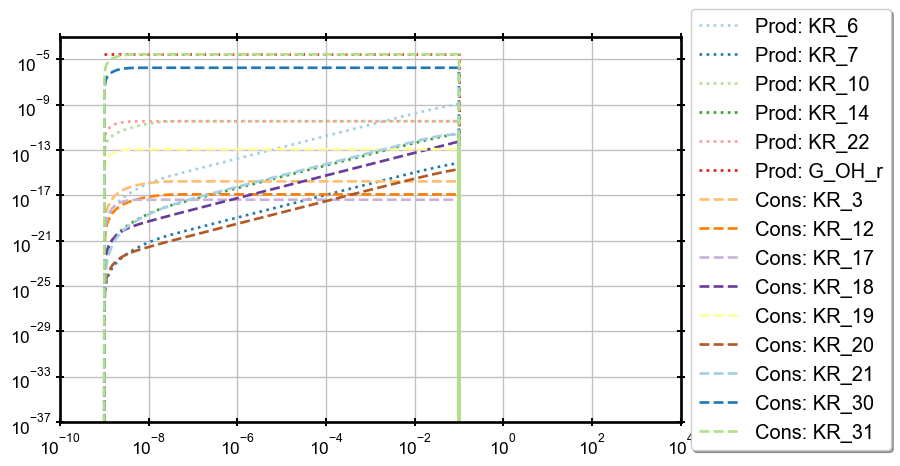

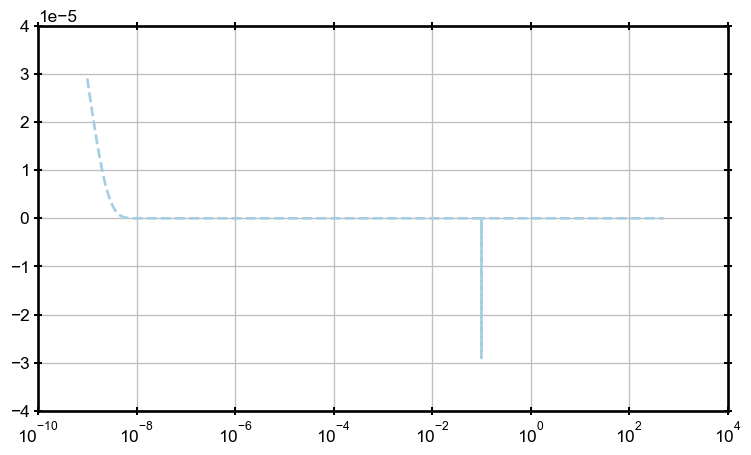

In [16]:
species = "OH_r"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

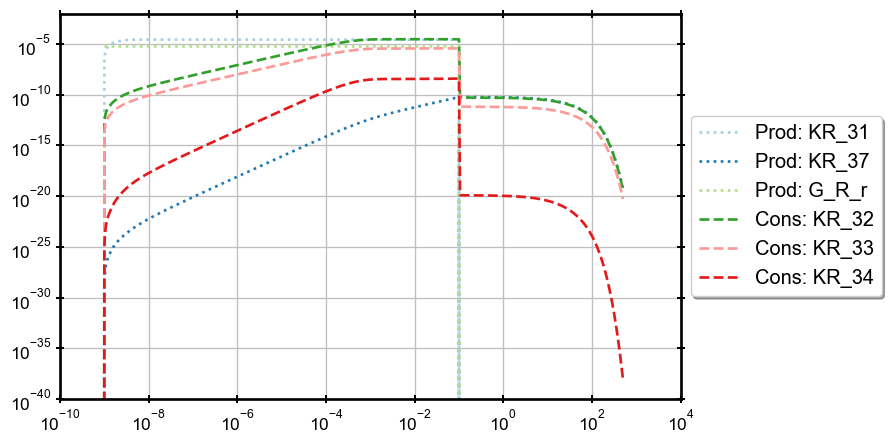

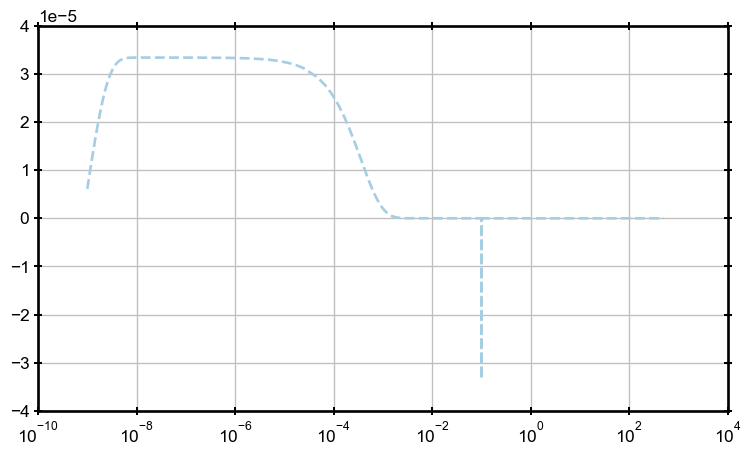

In [17]:
species = "R_r"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in sim.env.reactions_involving_product(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in sim.env.reactions_involving_reactant(species):
        ax.loglog(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    RPlot.set_legend_right(ax)
with fig_man.open(f"reaction rate balance for {species}") as (fig, ax):
    ax.semilogx(df_b.index, df_b[species], marker="")

### Acid/Base

In [23]:
part = env.reactions.acid_base[2].compute_partition(1, 1e-7)
1/ (part.dHA / part.dA)

125.89254117941663

## Debug Enzimatic reactions

Enzi matrices:  
1. Ez_substrate VECTOR ==> substrate selection  
1. Ez_enzyme    VECTOR ==> Enzyme selection  
1. Ez_kmki      MATRIX ==> Line 0: K micha, Line 1: k_value 

Error is 
> Mismatch dimensions  
> Line: beta = np.matmul(Enzi[2][0, :] * Enzi[2][1, :], Enzi[0])

In [10]:
y0[10] = 4

In [14]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y0, Enzi[0])
KK = np.prod(Enzi[2], axis=0)

array([72820000.])

In [20]:
Enzi[2][1,:] * E * S 

array([21184000.])

In [21]:
MM = Enzi[2][1, :] * E * S / (Enzi[2][0, :] + S)
MM

array([4153725.49019608])

In [22]:
np.matmul(Enzi[0], MM)

array([      0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        , 4153725.49019608,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ])

 ## Debug Jacobian

In [140]:
list(sim.env.species.iter_cst_species())

[CstSpecies<H2O, cc=6e+01, index= 3>,
 CstSpecies<catalase, cc=4, index= 4>,
 CstSpecies<H_plus, cc=1e-07, index= 5>,
 CstSpecies<OH_minus, cc=1e-07, index= 6>]

In [137]:
cst_sp

array([5.5e+01, 1.0e-07, 1.0e-07, 0.0e+00])

In [141]:
for elt in sim.env.iter_DynSpecies():
    print(elt)

SimSpecies<e_aq, index=0>
SimSpecies<H_r, index=1>
SimSpecies<H2, index=2>


In [121]:
y = np.array([3,2,1])
jac = jacobian(0,y,sim.beam, **sim.mat)
matprint(jac)

   -550  -3.6e-10  0  
    550  -1.8e-10  0  
2.4e-10   1.8e-10  0  


In [144]:
cst_sp, AB_mat, Ki_mat, Gi_mat, Ez_mat = sim.mat["cst_sp"], sim.mat["AB_mat"], sim.mat["Ki_mat"], sim.mat["Gi_mat"], sim.mat["Ez_mat"]
yy = np.append(y, cst_sp)
yy[3] = 1
yy

array([3.e+00, 2.e+00, 1.e+00, 1.e+00, 4.e+00, 1.e-07, 1.e-07])

1) Check Ki_mat[3]

In [45]:
for sp in sim.env.iter_DynSpecies():
    print(f"Species: d/d{sp.label}")
    for idx in range(Ki_mat[3].shape[2]):
        matprint(Ki_mat[3][:,:,idx, sp.index])
        print()

Species: d/de_aq
0  2  
0  0  
0  0  
1  0  
0  0  
0  0  

nan  0  
nan  1  
nan  0  
nan  0  
nan  0  
nan  0  

nan  nan  
nan  nan  
nan  nan  
nan  nan  
nan  nan  
nan  nan  

Species: d/dH_r
0  1  
0  0  
0  0  
0  0  
0  0  
0  0  

0  1  
0  0  
0  0  
0  0  
0  0  
0  0  

0  nan  
0  nan  
0  nan  
0  nan  
0  nan  
0  nan  

Species: d/dH2
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

0  0  
0  0  
0  0  
0  0  
0  0  
0  0  



2. Check jacobian calc

In [93]:
yy = np.append(y, cst_sp)
yy[3] = 1

In [94]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", yy, Ki_mat[3]), nan=1)
for sp in sim.env.iter_species():
    print(f"Species: d/d{sp.label}")
    matprint(res[:,:,sp.index])
    print()

Species: d/de_aq
1  1  1  
6  2  1  

Species: d/dH_r
0  0  0  
3  3  1  

Species: d/dH2
0  0  0  
0  0  0  

Species: d/dH2O
0  0  0  
0  0  0  

Species: d/dH_plus
0  0  0  
0  0  0  

Species: d/dOH_minus
0  0  0  
0  0  0  



In [95]:
res = np.prod(res, axis=1).T * Ki_mat[0]
np.matmul(Ki_mat[1], res.T)

array([[-490., -360.,    0.,    0.,    0.,    0.],
       [-230., -180.,    0.,    0.,    0.,    0.],
       [ 240.,  180.,    0.,    0.,    0.,    0.],
       [   0.,    0.,    0.,    0.,    0.,    0.],
       [   0.,    0.,    0.,    0.,    0.,    0.],
       [   0.,    0.,    0.,    0.,    0.,    0.]])

OK.
Now check Enzymatic contrib

In [153]:
E = np.matmul(yy, Ez_mat[1])
S = np.matmul(yy, Ez_mat[0]) + Ez_mat[2][0, :]
JEnzi = np.prod(Ez_mat[2], axis=0) * E / S / S
JEnzi = np.multiply(Ez_mat[0], JEnzi[None, :])

In [157]:
matprint(np.matmul(Ez_mat[3], JEnzi.T))

0         0  0  0  0  0  0  
0  -2.28928  0  0  0  0  0  
0   2.28928  0  0  0  0  0  
0         0  0  0  0  0  0  
0         0  0  0  0  0  0  
0         0  0  0  0  0  0  
0         0  0  0  0  0  0  


In [162]:
Jab = AB_mat[0] + AB_mat[2].sum(axis=1)
AB_mat[2]

array([], shape=(7, 0), dtype=float64)

In [18]:
y = np.array(np.arange(2,31))
for sp in sim.env.species:
    print(f"{sp.index:02d}) {sp.label} {' '*(15-len(sp.label))} = {y[sp.index]:.2g}")

00) OH_r             = 2
01) O_r_minus        = 3
02) H2O2             = 4
03) HO2_minus        = 5
04) HO2_r            = 6
05) O2_r_minus       = 7
06) e_aq             = 8
07) H_r              = 9
08) H2               = 10
09) O2               = 11
10) O2_minus_minus   = 12
11) O3_minus         = 13
12) Fe_plus_plus_plus  = 14
13) HO_r             = 15
14) RH_r             = 16
15) R_r              = 17
16) ROO_r            = 18
17) ROH              = 19
18) RO               = 20
19) ROOH             = 21
20) H2O              = 22
21) catalase         = 23
22) Fe_plus_plus     = 24
23) GSH              = 25
24) RH               = 26
25) unsat_lipid      = 27
26) H_plus           = 28
27) OH_minus         = 29
28) trash            = 30


In [34]:
y = np.append(sol.y[:,100], sim.mat["cst_sp"])
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, sim.mat["Ki_mat"][3]), nan=1)
res = np.prod(res, axis=1).T * sim.mat["Ki_mat"][0][None,:]
res = np.matmul(sim.mat["Ki_mat"][1], res.T)

In [35]:
matprint(res)

-1.06504e+09       9.9e+07     22.7044   5.16226         0      -2.17991    1.5518e+06       13244.6  -0.0114445             0  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
         4.2  -1.80097e+11           0         0         0  -2.05825e-06  -7.54693e-05             0           0  -1.23495e-05  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
     2.99737             0    -22.7044         0   6.35972       9796.16  -1.55179e+06      -12307.5           0             0  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
    -21.1107             0           0  -9.24958         0             0      -9.85166             0           0             0  0  0  0  0  0             0         0  0  0  0  0  0  0  0  0  0  0  0  0  
     21.1107             0           0   2.04366  -6.35972             0             0   1.04999e+12           0       13.3554  0  0  0  0  0             0         0  0  0  0  0  0  0 

In [ ]:

res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    matprint(res[:,:,sp.index])
    print()

e_aq
 2  1  
22  1  
12  1  
 5  1  
 6  1  
 3  1  
 7  1  
 8  1  
14  1  
10  1  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  



In [ ]:
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    for _ in range(ki_mat[3].shape[2]):
        matprint(ki_mat[3][:,:,_,sp.index])
        print()

e_aq
1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0

## Enzimatic contrib

In [66]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y, Enzi[0]) + Enzi[2][0,:]
JEnzi = np.prod(Enzi[2], axis=0) * E / S / S # Vector...
np.multiply(Enzi[0], JEnzi[None,:])

array([[    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [33946.73970048],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ]])

In [41]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y, Enzi[0]) + Enzi[2][0,:]
JEnzi = np.prod(Enzi[2], axis=0) * E / S / S # Vector...
JEnzi = np.multiply(Enzi[0], JEnzi)
JEnzi = np.matmul(Enzi[3], JEnzi.T)
print(JEnzi.shape)
matprint(JEnzi)

(29, 29)
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  -67893.5  0

In [57]:
Jab = ab_mat[0] + ab_mat[2].sum(axis=1)
matprint(np.multiply(JEnzi, Jab[None,:]))

0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  -67892.1  0  0  0  0

In [58]:
ab_mat[0] + ab_mat[2].sum(axis=1)

array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       9.99987411e-01, 1.25890956e-05, 9.99980048e-01, 1.99522251e-05,
       7.88068385e-03, 9.92119316e-01, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00])

In [61]:
ab_mat[2]

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [9.99987411e-01, 0.00000000e+00, 0.00000000e+00],
       [1.25890956e-05, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 9.99980048e-01, 0.00000000e+00],
       [0.00000000e+00, 1.99522251e-05, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 7.88068385e-03],
       [0.00000000e+00, 0.00000000e+00, 9.92119316e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000